# Monitoring an experiment: confidence sequences

An online experiment, a staged rollout or a trial is rarely analysed only once. Results are checked
every day and the experiment is stopped when the effect looks clear. A 95% confidence interval is
not made for that: it covers the effect with probability 0.95 at *one* sample size fixed in
advance. Each additional look is another chance for a false alarm, and with many looks the chance
that some look shows a "significant" effect that is not there is far above 5%.

A **confidence sequence** covers the effect at *all* sample sizes at once:

$$
P\bigl(\theta \in C_t \text{ for every } t\bigr) \ge 1 - \alpha .
$$

It can be checked after every new observation and the experiment stopped at any time, and the error
rate stays at $\alpha$. dml-rs computes the asymptotic confidence sequences of Waudby-Smith, Arbour,
Sinha, Kennedy and Ramdas (2024) for every model. Their theory covers doubly robust estimators with
cross-fitted nuisance models, so covariates can be used to reduce the variance, as in any DML fit.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import dml_rs

pd.set_option("display.precision", 4)


def experiment(n, effect, rng):
    # Users arrive one by one; treatment is randomised 50/50. Pre-period
    # activity x predicts the outcome, which lets the DML fit cut noise.
    x = rng.normal(size=(n, 3))
    d = (rng.random(n) < 0.5).astype(float)
    y = effect * d + x[:, 0] + 0.5 * x[:, 1] ** 2 + rng.normal(size=n)
    return x, y, d


def model():
    return dml_rs.IRM(dml_rs.Ols(), dml_rs.LogisticRegression())


x, y, d = experiment(20_000, effect=0.06, rng=np.random.default_rng(1))

## Following one experiment

We look after every 500 users. `ConfidenceSequence.run` refits the model on all data so far at each
look. `opt_time` is the sample size where the sequence is tightest; it has to be chosen before
seeing the data, here 2000 users.

In [2]:
looks = list(range(500, 20_001, 500))
cs = dml_rs.ConfidenceSequence(level=0.95, opt_time=2000)
cs.run(model(), looks, X=x, y=y, d=d)
cs.summary.iloc[::4]

,n,coef,std err,95% CS lower,95% CS upper,anytime P
estimate,,,,,,
d,500,0.0439,0.1167,-0.3371,0.4249,1.0000
d,2500,0.1385,0.0499,-0.0132,0.2731,0.1007
d,4500,0.1157,0.0365,0.0046,0.2241,0.0354
d,6500,0.1013,0.0300,0.0095,0.1945,0.0205
d,8500,0.0649,0.0263,0.0095,0.1474,0.0205
d,10500,0.0495,0.0237,0.0095,0.1243,0.0205
d,12500,0.0443,0.0217,0.0095,0.1133,0.0205
d,14500,0.0551,0.0203,0.0095,0.1117,0.0205
d,16500,0.0576,0.0190,0.0095,0.1117,0.0205


In [3]:
print("zero first excluded at n =", cs.first_exclusion(0.0)[0])

zero first excluded at n = 4000


The intervals of all looks hold together, so the sequence reported at each look is the running
intersection (`lower_`, `upper_`), and the anytime p-value is the running minimum. Repeated ordinary
95% intervals from the same fits are narrower, but they do not hold together:

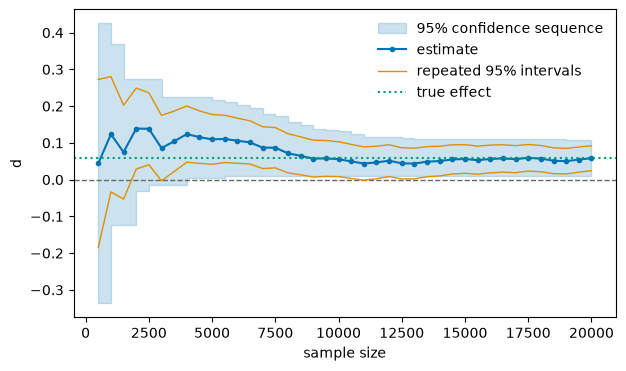

In [4]:
fits = [model().fit(x[:t], y[:t], d[:t]) for t in looks]
ci = np.array([f.confint(0.95)[0] for f in fits])

ax = cs.plot()
ax.plot(
    looks, ci[:, 0], color="#DE8F05", lw=1, label="repeated 95% intervals"
)
ax.plot(looks, ci[:, 1], color="#DE8F05", lw=1)
ax.axhline(0.06, color="#029E73", ls=":", label="true effect")
ax.legend(frameon=False);

## Why it matters: A/A tests

Run experiments with **no effect** and stop at the first look that excludes zero. With repeated
ordinary intervals, how often does that happen by chance? Each experiment has up to 10,000 users and
20 looks.

In [5]:
looks_aa = list(range(500, 10_001, 500))
reps = 150
alarms = {"repeated 95% intervals": 0, "95% confidence sequence": 0}
for r in range(reps):
    xa, ya, da = experiment(
        looks_aa[-1], 0.0, np.random.default_rng(100 + r)
    )
    ci_alarm = cs_alarm = False
    lower, upper = -np.inf, np.inf
    for t in looks_aa:
        fit = model().fit(xa[:t], ya[:t], da[:t])
        lo, hi = fit.confint(0.95)[0]
        ci_alarm |= lo > 0 or hi < 0
        lo, hi = fit.confidence_sequence(0.95, opt_time=2000)[0]
        lower, upper = max(lower, lo), min(upper, hi)
        cs_alarm |= lower > 0 or upper < 0
    alarms["repeated 95% intervals"] += ci_alarm
    alarms["95% confidence sequence"] += cs_alarm
pd.Series(alarms) / reps

repeated 95% intervals     0.2267
95% confidence sequence    0.0133
dtype: float64

Peeking at ordinary intervals declares an effect in about a fifth of the experiments that have none.
The confidence sequence keeps false alarms below 5% however often it is checked.

## The price: wider intervals

Being allowed to look at any time costs width. At its tuning point `opt_time` the 95% sequence is
about 3.0 standard errors wide on each side, against 1.96 for a fixed-sample interval, and it widens
slowly, like $\sqrt{\log t}$, away from it. The half-width in standard errors after $t$ observations
is $\sqrt{2(u+1)/u\,\log(\sqrt{u+1}/\alpha)}$ with $u = t\rho^2$:

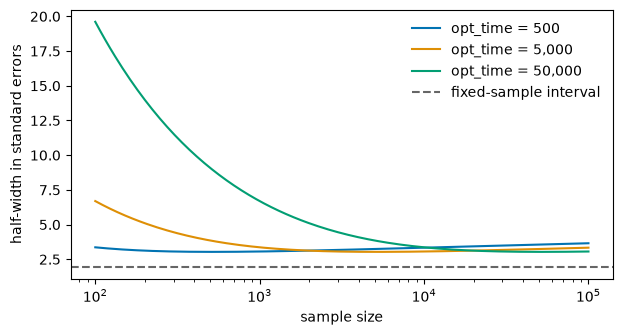

In [6]:
def half_width(t, opt_time, alpha=0.05):
    c = -2 * np.log(alpha)
    u = t * (c + np.log(c + 1)) / opt_time
    return np.sqrt(2 * (u + 1) / u * np.log(np.sqrt(u + 1) / alpha))


t = np.geomspace(100, 100_000, 200)
fig, ax = plt.subplots(figsize=(7, 3.5))
for opt_time, color in [
    (500, "#0173B2"),
    (5000, "#DE8F05"),
    (50_000, "#029E73"),
]:
    ax.plot(
        t,
        half_width(t, opt_time),
        color=color,
        label=f"opt_time = {opt_time:,}",
    )
ax.axhline(1.96, color="#666666", ls="--", label="fixed-sample interval")
ax.set_xscale("log")
ax.set_xlabel("sample size")
ax.set_ylabel("half-width in standard errors")
ax.legend(frameon=False);

A small `opt_time` gives tight intervals early and pays a little later; a large one the reverse.
Set it to the sample size at which a decision becomes plausible.

## Covariates shorten experiments

The standard error of a DML fit falls when the nuisance models explain part of the outcome, and the
confidence sequence narrows with it. Compare the stopping time with the pre-period covariates and
with an uninformative covariate (about a difference in means), over 100 experiments with an effect
of 0.06:

In [7]:
looks_stop = list(range(1000, 20_001, 1000))
stops = {"with covariates": [], "without": []}
for r in range(100):
    xs, ys, ds = experiment(
        looks_stop[-1], 0.06, np.random.default_rng(500 + r)
    )
    noise = np.random.default_rng(r).normal(size=(len(ys), 1))
    for name, features in [("with covariates", xs), ("without", noise)]:
        seq = dml_rs.ConfidenceSequence(opt_time=2000)
        seq.run(model(), looks_stop, X=features, y=ys, d=ds)
        stop = seq.first_exclusion(0.0)[0]
        stops[name].append(np.inf if stop is None else stop)
stopping = pd.DataFrame(stops)
pd.DataFrame(
    {
        "stopped by n = 20,000": np.isfinite(stopping).mean(),
        "median stopping n": stopping.median(),
    }
)

,"stopped by n = 20,000",median stopping n
with covariates,0.60,14000.0
without,0.43,inf


With the covariates, the experiment detects the effect sooner and more often: variance reduction and
valid sequential monitoring work together.

## Summary

- `model.confidence_sequence(level, opt_time)` gives the anytime-valid interval at a fit's sample
  size, and `model.anytime_pval` the matching p-value, for every model in dml-rs.
- `dml_rs.ConfidenceSequence` follows a study over its looks: `run` refits on growing prefixes
  (rows in arrival order) and `update` adds a fit. `summary`, `first_exclusion` and `plot` report
  the running intervals.
- Fix `opt_time` before the data come in. Clustered fits count clusters as the sample size.